,ten,quan,dan_so,lat,lon
0,Phường Thủ Dầu Một,NaN,91734,10.984000,106.653900
1,Phường Phú Lợi,NaN,109317,10.986270,106.679910
2,Phường Bình Dương,NaN,108497,11.060312,106.687951
3,Phường Phú An,NaN,53347,11.043726,106.618785
4,Phường Chánh Hiệp,NaN,56872,11.007737,106.643799


,ten,tuyen,trang_thai,lat,lon
0,Bến Thành,1,dang_hoat_dong,10.77075,106.69762
1,Nhà hát Thành phố,1,dang_hoat_dong,10.77551,106.70226
2,Ba Son,1,dang_hoat_dong,10.78199,106.70846
3,Văn Thánh,1,dang_hoat_dong,10.79605,106.71552
4,Tân Cảng,1,dang_hoat_dong,10.79858,106.72332


--- Kiểm tra wards: 168 dòng ---
Giá trị thiếu theo cột:
 ten       0
quan      0
dan_so    0
lat       0
lon       0
dtype: int64
Dòng trùng ['ten', 'quan']: 0
Toạ độ ngoài khung TP.HCM: 1
                ten      lat        lon
65  Đặc khu Côn Đảo  8.69032  106.60652
Wards sau khi làm sạch: 167/168 dòng (tổng dân số: 13,793,648)

--- Kiểm tra stations: 148 dòng ---
Giá trị thiếu theo cột:
 ten           0
tuyen         0
trang_thai    0
lat           0
lon           0
dtype: int64
Dòng trùng ['ten', 'tuyen']: 2
Toạ độ ngoài khung TP.HCM: 0
=> Station sau làm sach: 146/148 dòng
Số trạm đã có (Hoạt động + đang xây): 39
Số trạm quy hoạch: 107
Khoảng cách chim bay Bến Thành - Suối Tiên: 17.56 km


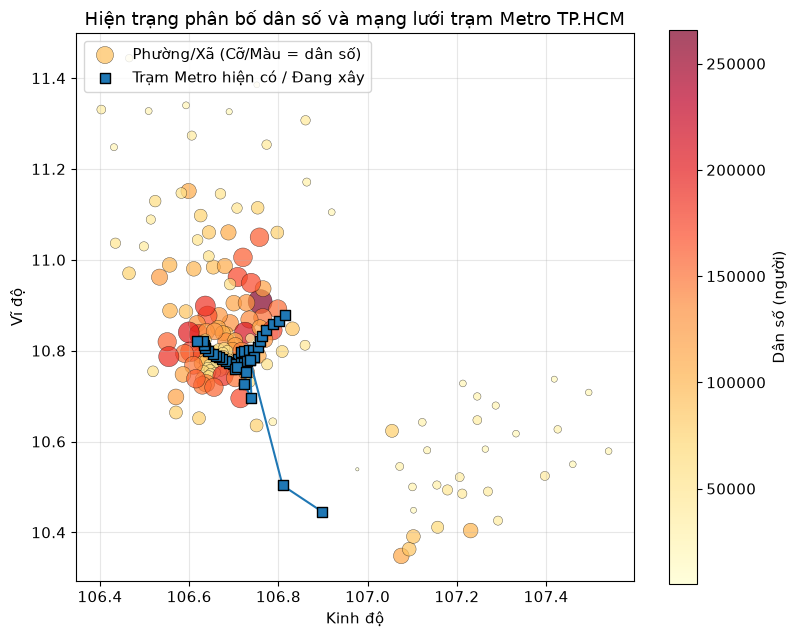

Tổng ứng viên sinh ban đầu: 15295
Tâm phường: 167
Lưới: 15128
Đã loại 14727 ứng viên, còn lại 568 ứng viên hợp lệ
Tâm phường: 149
Lưới: 419


,ten,lat,lon,nguon,id
0,Phường Thủ Dầu Một,10.984000,106.653900,tam_phuong,0
1,Phường Phú Lợi,10.986270,106.679910,tam_phuong,1
2,Phường Bình Dương,11.060312,106.687951,tam_phuong,2
3,Phường Phú An,11.043726,106.618785,tam_phuong,3
4,Phường Chánh Hiệp,11.007737,106.643799,tam_phuong,4


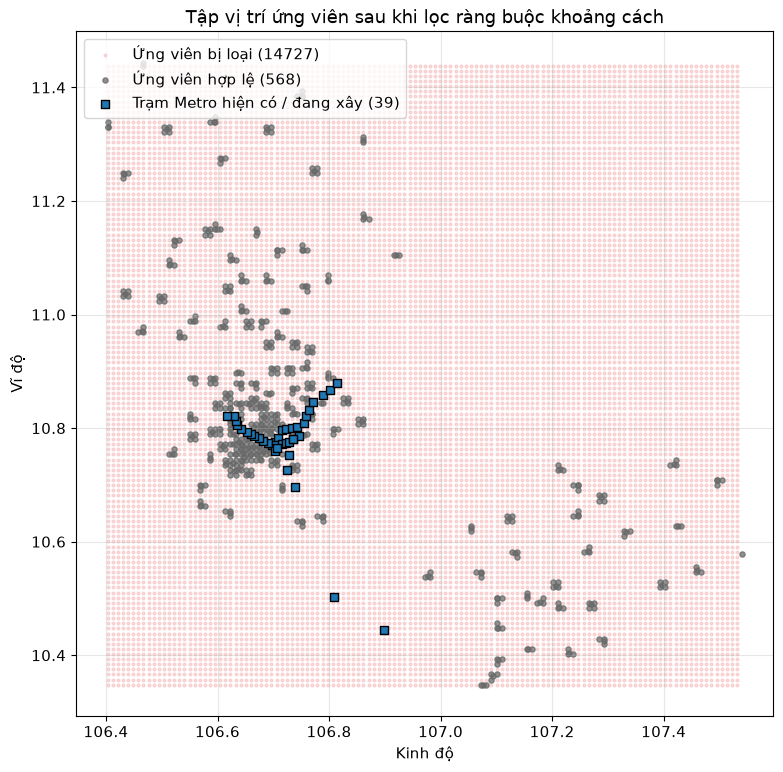

Kích thước D_CW: (568, 167) | D_CC: (568, 568) | D_CS: (568, 39)
Số phường đã được trạm hiện có phục vụ (R <= 1.0 KM): 18/167 phường
Dân số đã được trạm hiện có phục vụ: 1,241,783 / 13,793,648 (9.00%)
Số hàng xóm của 5 trạm (N_CAND=568): 3383 | Thời gian sinh + chấm điểm: 0.259s
Trạng thái ban đầu: {'so_tram_moi': 5, 'dan_so_phuc_vu': 1862927.0, 'ty_le_phuc_vu': np.float64(0.13505687545455705), 'chieu_dai_km': 62.99747512328379, 'chi_phi': 130.99495024656758, 'hinh_phat': 1.6198990049313517, 'diem': -8.226428049695338}
Sau leo đồi thử nghiệm: {'so_tram_moi': 10, 'dan_so_phuc_vu': 2913567.0, 'ty_le_phuc_vu': np.float64(0.21122526832640648), 'chieu_dai_km': 14.536293311823878, 'chi_phi': 39.07258662364775, 'hinh_phat': 0.0, 'diem': 0.13308009507911095}
=> TẤT CẢ KIỂM THỬ ĐỀU QUA


In [14]:
%run ./dev-v1.ipynb

## Cầu nối tên hàm giữa Khối 1-3 và Khối 4

TV1 đặt tên hàm theo snake_case (`random_state`, `get_neighbors`), còn Khối 4
gọi theo camelCase (`randomState`, `getNeighbors`). Cell dưới gán tên mới cho
cùng một hàm, không sao chép hay sửa gì code của TV1.

Hai tên trỏ về chung một hàm, nên sau này TV1 sửa `dev-v1.ipynb` thì Khối 4
tự động dùng bản mới.

In [15]:
# ====== CẦU NỐI sang Khối 1-3 của TV1 ======
# TV1 dùng snake_case, Khối 4 gọi camelCase. Gán tên mới cho cùng một hàm.

randomState = random_state
getNeighbors = get_neighbors
randomNeighbor = random_neighbor

## 4.1 localBeamSearch

Giữ beamWidth phương án song song. Mỗi vòng chỉnh nhẹ tất cả phương án
đang có, gom chung một rổ, rồi giữ lại beamWidth phương án điểm cao nhất.

beamWidth = 1 chính là Hill Climbing.


In [16]:
def localBeamSearch(beamWidth,maxRounds=100,maxNoGain=10, seed=0,numStations=None, weights=DEFAULT_WEIGHTS):
    rng = np.random.default_rng(seed)
    # tạo phương án ngẫu nhiên làm điểm xuất phát
    beam = [randomState(numStations,rng) for _ in range(beamWidth)]
    beamScores = np.array([objective(state,weights) for state in beam])
    
    # ghi dữ liệu ban đầu
    bestIndex = int(np.argmax(beamScores))
    bestState = beam[bestIndex]
    bestScore = float(beamScores[bestIndex])
    
    history = [{
        "round": 0,
        "bestScore": bestScore,
        "beamBest": float(beamScores.max()),
        "beamMean": float(beamScores.mean()),
    }]
    noGainRounds = 0
    
    # với phương án đang có, chỉnh nhẹ 1 trạm dời sang trạm khác 
    for roundNo in range(1,maxRounds+1):
        neighborPool = list({
            newState
            for state in beam
            for newState in getNeighbors(state)
        })
        
        if not neighborPool:
            break
        
        neighborScores = np.array([objective(state,weights) for state in neighborPool])
        topIndexs = np.argsort(neighborScores)[::-1][:beamWidth]
        beam = [neighborPool[i] for i in topIndexs]
        beamScores = neighborScores[topIndexs]
        
        # beamScores[0] tốt nhất của riêng vòng này
        # bestScore tốt nhất từ đầu tới giờ
        if beamScores[0] > bestScore:
            bestState = beam[0]
            bestScore = float(beamScores[0])
            noGainRounds = 0
        else:
            noGainRounds +=1 
        history.append({
            "round": roundNo,
            "bestScore": bestScore,
            "beamBest": float(beamScores[0]),
            "beamMean": float(beamScores.mean()),
        })
        
        # không được thì dừng lại việc thực thi
        if noGainRounds >= maxNoGain:
            break
        
    return bestState, bestScore, history
    


## 4.2 stochasticLocalBeamSearch

Lấy top-k tuyệt đối thì cả `beamWidth` suất thường rơi hết vào con cháu của
cùng một phương án. Beam mất đa dạng, `beamWidth` phương án gần như giống hệt
nhau, thuật toán thoái hoá thành Hill Climbing.

Bốc thăm thì phương án điểm thấp vẫn có cơ hội sống sót. Một cách bố trí trạm
tạm thời kém, sau vài vòng chỉnh sửa, có thể vượt lên dẫn đầu.

In [17]:
def stochasticLocalBeamSearch(beamWidth, maxRounds=100, maxNoGain=10, seed=0,
                              numStations=None, weights=DEFAULT_WEIGHTS):
    rng = np.random.default_rng(seed)
    
    # bốc đại 1 beamWidth phương án để có chỗ bắt đầu
    beam = [randomState(numStations,rng) for _ in range(beamWidth)]
    beamScores = np.array([objective(state,weights) for state in beam])
    
    bestIndex = int(np.argmax(beamScores))
    bestState = beam[bestIndex]
    bestScore = float(beamScores[bestIndex])
    
    history = [{
        "round": 0,
        "bestScore": bestScore,
        "beamBest": float(beamScores.max()),
        "beamMean": float(beamScores.mean()),
    }]

    noGainRounds = 0
    
    for roundNo in range(1,maxRounds+1):
        # gom vào 1 rổ chung
        neighborPool = list({
            newState
            for state in beam
            for newState in getNeighbors(state)
        })

        if not neighborPool:
            break
        
        neighborScores = np.array([objective(state, weights) for state in neighborPool])

        # đổi điểm thành số vé. điểm có thể âm nên dời tất cả lên dương
        # bằng cách trừ đi điểm thấp nhất. cộng baseTickets để phương án bét vẫn còn vé
        scoreSpread = neighborScores.max() - neighborScores.min()
        baseTickets = scoreSpread * 0.1 if scoreSpread > 0 else 1.0
        tickets = neighborScores - neighborScores.min() + baseTickets
        pickProbs = tickets / tickets.sum()
        
        # lấy beamWidth phương thức khác nhau
        pickedIndexes = rng.choice(len(neighborPool), size=beamWidth, replace=False, p=pickProbs)
        beam = [neighborPool[i] for i in pickedIndexes]
        beamScores = neighborScores[pickedIndexes]
        
        # dùng argMax để tìm phương án tốt nhất của vòng
        roundBestIndex = int(np.argmax(beamScores))
        roundBestScore = float(beamScores[roundBestIndex])
        
        if roundBestScore > bestScore:
            bestState = beam[roundBestIndex]
            bestScore = roundBestScore
            noGainRounds = 0
        else:
            noGainRounds += 1

        history.append({
            "round": roundNo,
            "bestScore": bestScore,
            "beamBest": roundBestScore,
            "beamMean": float(beamScores.mean()),
        })
        
        # thực hiện dùng nếu k có kết quả
        if noGainRounds >= maxNoGain:
            break
        
    return bestState, bestScore, history
        
        

## 4.3 randomRestartBeamSearch


In [18]:
def randomRestartBeamSearch(numRestarts, beamWidth, maxRounds=20, maxNoGain=10,
                            seed=0, numStations=None, weights=DEFAULT_WEIGHTS,
                            searchFn=localBeamSearch):
    bestState = None
    bestScore = -np.inf
    history = []
    
    # Mỗi lần chạy phải đổi seed, không thì bốc trúng y hệt bộ phương án cũ
    # và chạy lại numRestarts lần cũng chỉ ra đúng một kết quả
    for restartNo  in range(numRestarts):
        state, score, runHistory = searchFn(
            beamWidth,
            maxRounds=maxRounds,
            maxNoGain=maxNoGain,
            seed=seed + restartNo,
            numStations=numStations,
            weights=weights,
        )
        
        # Gắn thêm số thứ tự lần chạy vào nhật ký, để Khối 6 tách ra vẽ riêng
        # từng lần và thấy được lần nào ăn may lần nào xui
        for row in runHistory:
            history.append({"restart": restartNo, **row})

        # Giữ lại phương án tốt nhất trong tất cả các lần chạy
        if score > bestScore:
            bestState = state
            bestScore = score

    return bestState, bestScore, history

# Khối 5. Thực nghiệm
Chạy các thuật toán ở Khối 4 trên dữ liệu thật, thu số liệu cho chương 4 báo cáo.

## 5.1 runExperiment — hàm chạy thí nghiệm dùng chung

Ba mục 5.2, 5.3, 5.4 thực chất là cùng một việc, chỉ khác thứ đem ra quét:

| Mục | Quét cái gì |
|---|---|
| 5.2 | `beamWidth` = 1, 3, 5, 10, 20 |
| 5.3 | Thuật toán = local beam, stochastic, random restart |
| 5.4 | Trọng số dân số / chi phí |


| Tên | Ý nghĩa |
|---|---|
| `searchFn` | Thuật toán đem chạy: `localBeamSearch`, `stochasticLocalBeamSearch`... |
| `numSeeds` | Chạy bao nhiêu lần, mặc định 20 |
| `label` | Tên cấu hình, để phân biệt các dòng trong bảng kết quả |
| `**params` | Tham số đưa thẳng cho `searchFn` (`beamWidth`, `maxRounds`, `weights`...) |

### Mỗi lần chạy ghi lại gì

| Cột | Ý nghĩa |
|---|---|
| `label` | Tên cấu hình |
| `seed` | Seed của lần chạy này |
| `score` | Điểm phương án tốt nhất tìm được |
| `numStations` | Phương án đó có mấy trạm |
| `rounds` | Chạy hết bao nhiêu vòng mới dừng |
| `seconds` | Thời gian chạy, dùng cho đồ thị đánh đổi ở Khối 6 |




In [19]:
import time

def runExperiment(algorithm,label, numSeeds=20,**params):

    rows = []

    for seed in range(numSeeds):
        start = time.perf_counter()
        bestState, bestScore, history = algorithm(seed=seed, **params)
        seconds = time.perf_counter() - start
        
        numRuns = len({row["restart"] for row in history}) if "restart" in history[0] else 1
        
        rows.append({
            "label": label,
            "seed": seed,
            "score": bestScore,
            "numStations": len(bestState),
            "rounds": len(history) - numRuns,
            "seconds": seconds,
        })
        
    return pd.DataFrame(rows)


def summarize(df):
    return (df.groupby("label", sort=False)
              .agg(scoreMean=("score", "mean"),
                   scoreStd=("score", "std"),
                   scoreMax=("score", "max"),
                   stationsMean=("numStations", "mean"),
                   roundsMean=("rounds", "mean"),
                   secondsMean=("seconds", "mean"))
              .round(4)
              .reset_index())